# Online Shoppers — Final decision tree project (from scratch)

**Research question:** Can a decision tree implemented from scratch identify online purchases with a useful balance of **precision and recall**?

This notebook follows the project methodology: dataset description → reproducible 60/20/20 split → preprocessing → mathematical implementation → verification → comparison with scikit-learn → validation-based model selection → **one final test** → interpretation.

**Important:** The data are imbalanced (~15.5% purchases). Good precision **and** recall cannot be guaranteed. We report actual outcomes, including failure to meet a target. We do **not** tune against the test set. We preserve the original 16 predictors (excluding `PageValues` and target `Revenue`).

## 1. Load the original dataset
Upload your existing `online_shoppers_intention.csv` when requested. No new data source is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

try:
    from google.colab import files
    uploaded = files.upload()
    filename = next((k for k in uploaded if k.lower().endswith('.csv')), None)
    if filename is None:
        raise ValueError('Upload online_shoppers_intention.csv')
except ImportError:
    filename = 'online_shoppers_intention.csv'

data = pd.read_csv(filename)
print('Dataset shape:', data.shape)
print('Missing values:', int(data.isna().sum().sum()))
print('Duplicated rows:', int(data.duplicated().sum()))
print(data['Revenue'].value_counts())
print('Purchase rate:', round(data['Revenue'].astype(int).mean()*100,2), '%')


Dataset shape: (12330, 18)
Missing values: 0
Duplicated rows: 125
Revenue
False    10422
True      1908
Name: count, dtype: int64
Purchase rate: 15.47 %


## 2. Features and the original shuffle/split

We use the **same selection and split algorithm** as `src/split_data.py`: 16 features, shuffled indices using seed 42, first 20% test, next 20% validation, remaining 60% train. We preserve this order so that results are comparable to the earlier project.

Train: 7398 Validation: 2466 Test: 2466
Training purchase rate = 15.22%
Validation purchase rate = 16.34%
Test purchase rate = 15.37%


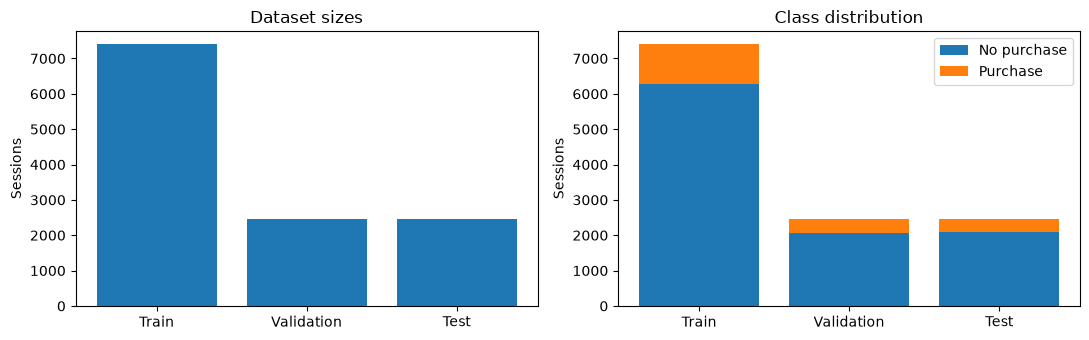

In [2]:
features = [
    'Administrative','Administrative_Duration','Informational','Informational_Duration',
    'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','SpecialDay',
    'Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend'
]
categories = ['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']
X = data[features]
y = data['Revenue'].astype(int)
n = len(data)
indices = np.random.default_rng(42).permutation(n)
n_test = round(0.2*n)
n_val = round(0.2*n)
test_idx = indices[:n_test]
val_idx = indices[n_test:n_test+n_val]
train_idx = indices[n_test+n_val:]
X_train, X_val, X_test = X.iloc[train_idx].copy(), X.iloc[val_idx].copy(), X.iloc[test_idx].copy()
y_train, y_val, y_test = y.iloc[train_idx].to_numpy(), y.iloc[val_idx].to_numpy(), y.iloc[test_idx].to_numpy()
assert len(np.unique(indices)) == n
print('Train:',len(y_train),'Validation:',len(y_val),'Test:',len(y_test))
for name,yy in [('Training',y_train),('Validation',y_val),('Test',y_test)]:
    print(name, 'purchase rate =', f'{np.mean(yy)*100:.2f}%')
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].bar(['Train','Validation','Test'], [len(y_train),len(y_val),len(y_test)])
axs[0].set(title='Dataset sizes',ylabel='Sessions')
axs[1].bar(['Train','Validation','Test'], [np.sum(y_train==0),np.sum(y_val==0),np.sum(y_test==0)],label='No purchase')
axs[1].bar(['Train','Validation','Test'], [np.sum(y_train==1),np.sum(y_val==1),np.sum(y_test==1)],bottom=[np.sum(y_train==0),np.sum(y_val==0),np.sum(y_test==0)],label='Purchase')
axs[1].set(title='Class distribution',ylabel='Sessions');axs[1].legend()
plt.tight_layout();plt.show()

## 3. One-hot encoding (fit columns on training only)

As in your `src/preprocessing.py`, categorical columns are converted to text and dummy-encoded. Validation/test columns are aligned to the columns found in training; unknown categories receive all zeros.

In [3]:
for col in categories:
    X_train[col] = X_train[col].astype(str)
    X_val[col] = X_val[col].astype(str)
    X_test[col] = X_test[col].astype(str)
train_encoded = pd.get_dummies(X_train, columns=categories, dtype=float)
val_encoded = pd.get_dummies(X_val, columns=categories, dtype=float).reindex(columns=train_encoded.columns,fill_value=0.0)
test_encoded = pd.get_dummies(X_test, columns=categories, dtype=float).reindex(columns=train_encoded.columns,fill_value=0.0)
X_train_ready = train_encoded.to_numpy(dtype=float)
X_val_ready = val_encoded.to_numpy(dtype=float)
X_test_ready = test_encoded.to_numpy(dtype=float)
assert X_train_ready.shape[1] == X_val_ready.shape[1] == X_test_ready.shape[1]
assert all(np.isfinite(a).all() for a in [X_train_ready,X_val_ready,X_test_ready])
print('Shapes:',X_train_ready.shape,X_val_ready.shape,X_test_ready.shape)

Shapes: (7398, 72) (2466, 72) (2466, 72)


## 4. The mathematics of the weighted decision tree

A decision tree recursively splits observations, preferring more homogeneous child nodes.

- **Gini impurity:** $G=1-p_0^2-p_1^2$, using *weighted* class proportions if observation weights are supplied.
- **Split impurity:** $G_{split}=\frac{W_L}{W_L+W_R}G_L+\frac{W_R}{W_L+W_R}G_R$.
- **Leaf prediction:** select the class with the greater **total weight** in the leaf.
- **Sample weights:** non-purchase weight $1$; purchase weight $w$ (selected on validation).

`sample_weight=None` gives exactly the original equal-weight behavior. We keep the original *quantile approximation* for continuous split thresholds: this is simpler and faster, but may differ from scikit-learn's exhaustive threshold search.

In [4]:
# Calculating Gini impurity
def gini(y, sample_weight=None):
    y = np.asarray(y)
    if len(y) == 0:
        return 0.0
    if sample_weight is None:
        sample_weight = np.ones(len(y))
    sample_weight = np.asarray(sample_weight, dtype=float)
    total_weight = np.sum(sample_weight)
    if total_weight == 0:
        return 0.0
    p = np.sum(sample_weight[y == 1]) / total_weight
    return 1 - p**2 - (1-p)**2

# Calculating weighted Gini impurity
def weighted_gini(y_left, y_right, w_left=None, w_right=None):
    if w_left is None:
        w_left = np.ones(len(y_left))
    if w_right is None:
        w_right = np.ones(len(y_right))
    total_left, total_right = np.sum(w_left), np.sum(w_right)
    total = total_left + total_right
    if total == 0:
        return 0.0
    return ((total_left/total)*gini(y_left,w_left)
            + (total_right/total)*gini(y_right,w_right))

# Finding the best feature and threshold
def best_split(X, y, min_samples_leaf=20, sample_weight=None):
    if sample_weight is None:
        sample_weight = np.ones(len(y))
    sample_weight = np.asarray(sample_weight, dtype=float)
    best_feature, best_threshold = None, None
    best_score = gini(y,sample_weight)
    for j in range(X.shape[1]):
        values = np.unique(X[:,j])
        if len(values) <= 1:
            continue
        if len(values) <= 16:
            thresholds = (values[:-1]+values[1:])/2
        else:
            thresholds = np.unique(np.quantile(values,np.linspace(0,1,17)[1:-1]))
        for t in thresholds:
            left = X[:,j] <= t
            right = ~left
            if left.sum() < min_samples_leaf or right.sum() < min_samples_leaf:
                continue
            score = weighted_gini(y[left],y[right],sample_weight[left],sample_weight[right])
            if score < best_score - 1e-12:
                best_score, best_feature, best_threshold = score, j, t
    return best_feature,best_threshold

# Building the decision tree
def build_tree(X,y,depth=0,max_depth=5,min_samples_leaf=20,sample_weight=None):
    y = np.asarray(y)
    if sample_weight is None:
        sample_weight = np.ones(len(y))
    sample_weight = np.asarray(sample_weight,dtype=float)
    weight_0 = np.sum(sample_weight[y==0])
    weight_1 = np.sum(sample_weight[y==1])
    prediction = int(weight_1 >= weight_0)
    if depth >= max_depth or gini(y,sample_weight) <= 1e-12:
        return {'prediction':prediction}
    j,t = best_split(X,y,min_samples_leaf,sample_weight)
    if j is None:
        return {'prediction':prediction}
    left = X[:,j] <= t
    right = ~left
    return {'feature':j,'threshold':t,
            'left':build_tree(X[left],y[left],depth+1,max_depth,min_samples_leaf,sample_weight[left]),
            'right':build_tree(X[right],y[right],depth+1,max_depth,min_samples_leaf,sample_weight[right])}

# Predicting one shopping session
def predict_one(x,tree):
    if 'prediction' in tree:
        return tree['prediction']
    if x[tree['feature']] <= tree['threshold']:
        return predict_one(x,tree['left'])
    return predict_one(x,tree['right'])

# Predicting all shopping sessions
def predict(X,tree):
    return np.array([predict_one(x,tree) for x in X])


## 5. Verify our implementation with small tests

These are the same mathematical checkpoints you had in `tree_scratch.py`, plus a weighted-vote check.

In [5]:
assert np.isclose(gini(np.array([0,0,0,0])),0.0)
assert np.isclose(gini(np.array([0,0,1,1])),0.5)
assert np.isclose(gini(np.array([0,0,0,0,1])),0.32)
assert np.isclose(weighted_gini(np.array([0,0]),np.array([1,1])),0.0)
assert np.isclose(weighted_gini(np.array([0,1]),np.array([0,1])),0.5)
assert np.isclose(weighted_gini(np.array([0,0,1]),np.array([1])),1/3)
X_small = np.array([[1],[2],[3],[4]],dtype=float)
y_small = np.array([0,0,1,1])
j,t = best_split(X_small,y_small,min_samples_leaf=1)
assert j==0 and np.isclose(t,2.5)
assert np.array_equal(predict(X_small,build_tree(X_small,y_small,max_depth=2,min_samples_leaf=1)),y_small)
assert build_tree(np.array([[0],[0],[0],[0.]],dtype=float),np.array([0,0,0,1]),max_depth=0,sample_weight=np.array([1,1,1,5]))['prediction']==1
print('OK — Gini, weighted Gini, best split, tree predictions, weighted vote')

OK — Gini, weighted Gini, best split, tree predictions, weighted vote


## 6. Metrics: accuracy, precision, recall and F1

**Precision:** of predicted purchases, how many really purchased?  
**Recall:** of actual purchases, how many were detected?  
**F1-score:** harmonic mean of precision and recall. Our primary model-selection metric is validation F1; we also inspect *both* precision and recall.  
**Accuracy:** fraction of all correct predictions — potentially misleading for an imbalanced dataset.

In [6]:
# Calculating classification metrics
def classification_metrics(y,y_pred):
    y=np.asarray(y);y_pred=np.asarray(y_pred)
    tp=np.sum((y==1)&(y_pred==1))
    fp=np.sum((y==0)&(y_pred==1))
    fn=np.sum((y==1)&(y_pred==0))
    accuracy=np.mean(y==y_pred)
    precision=tp/(tp+fp) if tp+fp>0 else 0.0
    recall=tp/(tp+fn) if tp+fn>0 else 0.0
    f1=2*precision*recall/(precision+recall) if precision+recall>0 else 0.0
    return {'Accuracy':accuracy,'Precision':precision,'Recall':recall,'F1':f1}


## 7. Validation: compare equal vs purchase-weighted trees, against scikit-learn

We use the **same 3 depths × 5 weights × 2 algorithms = 30 configurations** as your previous project. A weight of 1 reproduces the original tree. `min_samples_leaf=20` stays unchanged. This avoids a large, difficult-to-explain hyperparameter search.

**Selection rule:** among our from-scratch trees, prefer those with validation precision **at least 0.35** and recall **at least 0.35**, if any exist; select the highest F1 within that set. Otherwise select the highest F1 overall and state that the balance target was not met. These are illustrative research criteria, not a professor-imposed threshold.

In [7]:
# Comparing tree with scikit-learn
results = []
purchase_ratio = np.sum(y_train==0)/np.sum(y_train==1)
purchase_weights = [1.0,2.0,3.0,5.0,float(purchase_ratio)]
for depth in [3,5,7]:
    for purchase_weight in purchase_weights:
        sample_weight=np.where(y_train==1,purchase_weight,1.0)
        # Training decision tree
        tree=build_tree(X_train_ready,y_train,max_depth=depth,min_samples_leaf=20,sample_weight=sample_weight)
        # Evaluating decision tree
        scores=classification_metrics(y_val,predict(X_val_ready,tree))
        results.append({'Model':'Our tree','Depth':depth,'Purchase_weight':purchase_weight,**scores})
        # Training scikit-learn decision tree
        sklearn_tree=DecisionTreeClassifier(criterion='gini',max_depth=depth,min_samples_leaf=20,random_state=42)
        sklearn_tree.fit(X_train_ready,y_train,sample_weight=sample_weight)
        # Evaluating scikit-learn decision tree
        sk_scores=classification_metrics(y_val,sklearn_tree.predict(X_val_ready))
        results.append({'Model':'Scikit-learn','Depth':depth,'Purchase_weight':purchase_weight,**sk_scores})
table=pd.DataFrame(results)
assert len(table)==30
print('VALIDATION RESULTS')
display(table.round(4))

VALIDATION RESULTS


,Model,Depth,Purchase_weight,Accuracy,Precision,Recall,F1
0,Our tree,3,1.0000,0.8366,0.0000,0.0000,0.0000
1,Scikit-learn,3,1.0000,0.8366,0.0000,0.0000,0.0000
2,Our tree,3,2.0000,0.7997,0.3426,0.2457,0.2861
3,Scikit-learn,3,2.0000,0.7997,0.3436,0.2481,0.2882
4,Our tree,3,3.0000,0.7903,0.3293,0.2730,0.2985
5,Scikit-learn,3,3.0000,0.7956,0.3333,0.2506,0.2861
6,Our tree,3,5.0000,0.6139,0.2623,0.7519,0.3890
7,Scikit-learn,3,5.0000,0.6119,0.2628,0.7618,0.3908
8,Our tree,3,5.5702,0.5697,0.2465,0.7940,0.3762
9,Scikit-learn,3,5.5702,0.6119,0.2628,0.7618,0.3908


## 8. Select configuration **before** looking at test performance

To keep the experiment interpretable, we do not add a new probability-threshold subsystem. Our original weighted leaf vote is retained. The F1-selected model might not meet both precision and recall targets: if so, we report the limitation and do not claim success.

No model met both 35% targets; selected highest validation F1
SELECTED: {'Depth': 5, 'Purchase_weight': 5.5702, 'Accuracy': 0.7287, 'Precision': 0.3299, 'Recall': 0.6402, 'F1': 0.4354}
EQUAL WEIGHTS: {'Depth': 7, 'Purchase_weight': 1.0, 'Accuracy': 0.8297, 'Precision': 0.419, 'Recall': 0.1092, 'F1': 0.1732}


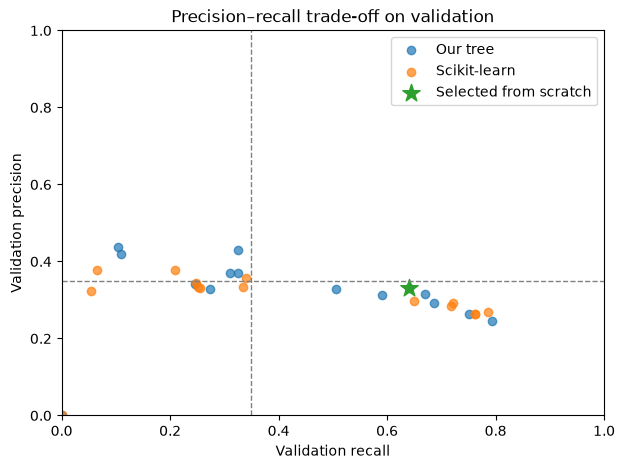

In [8]:
our_results=table[table['Model']=='Our tree'].copy()
balanced_candidates=our_results[(our_results['Precision']>=0.35)&(our_results['Recall']>=0.35)]
if len(balanced_candidates):
    selected=balanced_candidates.loc[balanced_candidates['F1'].idxmax()]
    selection_reason='Best validation F1 among models with precision >=35% and recall >=35%'
else:
    selected=our_results.loc[our_results['F1'].idxmax()]
    selection_reason='No model met both 35% targets; selected highest validation F1'
equal=our_results[np.isclose(our_results['Purchase_weight'],1.0)]
best_equal=equal.loc[equal['F1'].idxmax()]
print(selection_reason)
print('SELECTED:',selected[['Depth','Purchase_weight','Accuracy','Precision','Recall','F1']].round(4).to_dict())
print('EQUAL WEIGHTS:',best_equal[['Depth','Purchase_weight','Accuracy','Precision','Recall','F1']].round(4).to_dict())
fig,ax=plt.subplots(figsize=(7,5))
for model_name,part in table.groupby('Model'):
    ax.scatter(part['Recall'],part['Precision'],label=model_name,alpha=.7)
ax.scatter([selected['Recall']],[selected['Precision']],s=170,marker='*',label='Selected from scratch')
ax.axhline(.35,ls='--',lw=1,color='gray');ax.axvline(.35,ls='--',lw=1,color='gray')
ax.set(xlabel='Validation recall',ylabel='Validation precision',title='Precision–recall trade-off on validation',xlim=(0,1),ylim=(0,1))
ax.legend();plt.show()

## 9. Final test — only now evaluate selected configurations

Our final table reports the **equal-weight original**, the **selected weighted/equal scratch tree**, the scikit-learn tree at the **same depth and weight** (fair benchmark), and the always-no-purchase baseline. The test set must not be used to tune or choose the model.

FINAL TEST RESULTS


,Model,Accuracy,Precision,Recall,F1
0,Original scratch tree,0.8382,0.4000,0.1055,0.1670
1,Selected scratch tree,0.7283,0.3132,0.6438,0.4214
2,Scikit-learn (same settings),0.6115,0.2545,0.7916,0.3851
3,No-purchase baseline,0.8463,0.0000,0.0000,0.0000


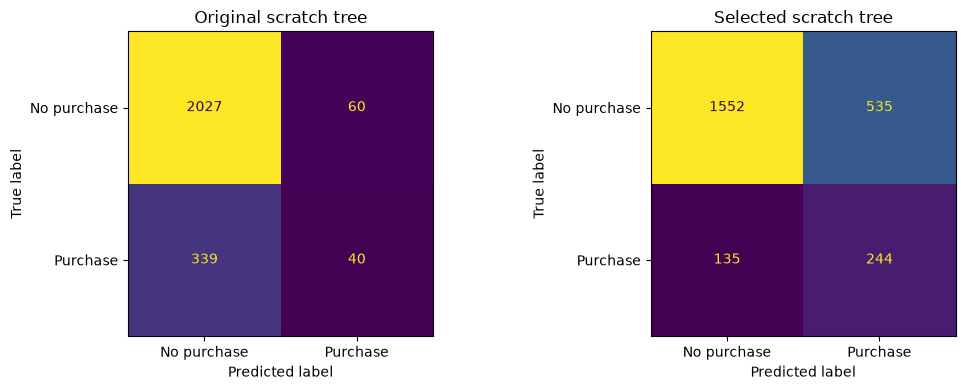

In [9]:
# Training the selected decision trees
def train_scratch_and_test(row,label):
    weights=np.where(y_train==1,float(row['Purchase_weight']),1.0)
    tree=build_tree(X_train_ready,y_train,max_depth=int(row['Depth']),min_samples_leaf=20,sample_weight=weights)
    pred=predict(X_test_ready,tree)
    return {'Model':label,**classification_metrics(y_test,pred)},pred
original_row,original_pred=train_scratch_and_test(best_equal,'Original scratch tree')
selected_row,selected_pred=train_scratch_and_test(selected,'Selected scratch tree')
sk_tree=DecisionTreeClassifier(criterion='gini',max_depth=int(selected['Depth']),min_samples_leaf=20,random_state=42)
sk_tree.fit(X_train_ready,y_train,sample_weight=np.where(y_train==1,float(selected['Purchase_weight']),1.0))
sk_pred=sk_tree.predict(X_test_ready)
sk_row={'Model':'Scikit-learn (same settings)',**classification_metrics(y_test,sk_pred)}
baseline_pred=np.zeros(len(y_test),dtype=int)
baseline_row={'Model':'No-purchase baseline',**classification_metrics(y_test,baseline_pred)}
final_table=pd.DataFrame([original_row,selected_row,sk_row,baseline_row])
print('FINAL TEST RESULTS')
display(final_table.round(4))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,pred,label in [(axs[0],original_pred,'Original scratch tree'),(axs[1],selected_pred,'Selected scratch tree')]:
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred,labels=[0,1]),display_labels=['No purchase','Purchase']).plot(ax=ax,colorbar=False)
    ax.set_title(label)
plt.tight_layout();plt.show()


## 10. Interpretation and project conclusion

Your earlier confirmed benchmark using the same original split and features was:

| Scratch tree | Test accuracy | Test precision | Test recall | Test F1 |
|---|---:|---:|---:|---:|
| Original equal-weight depth 7 | 0.8382 | 0.4000 | 0.1055 | 0.1670 |
| Purchase-weighted depth 5, weight 5.5702 | 0.7283 | 0.3132 | 0.6438 | 0.4214 |

These are **previously observed results**, not a promise for any modified selection criterion. Check the live output above for this notebook's selected configuration.

**Scientific conclusion:** Class weighting increases attention to the minority purchase class. It often raises recall while lowering precision and accuracy. A higher F1 does not automatically imply high precision and recall individually. If neither is sufficiently strong, the result is a limitation of the particular data/features/model configuration, not an implementation failure.

**Caveats:** 125 duplicate rows in the source data may be present in different partitions; the split is randomized but not stratified; our quantile threshold search is approximate; and `PageValues` remains excluded because its availability at prediction time is uncertain. These are explicit methodological limitations to discuss in your report. As earlier test results have already been inspected, treat any new tuning on these same data as exploratory rather than claiming a brand-new independent final assessment.

**Guidelines alignment:** central algorithm, Gini objective, recursion, prediction implemented independently; verified with assertions; scikit-learn only used as same-method benchmark; clear split, metrics, limitations and interpretation.